<h1>Monte Carlo Convergence in Estimating Pi Code</h1>

<h5>Adam Feldman and Luke Wilson</h5>

<h2>Simple Monte Carlo Simulation</h2>

For this setup, a simple program was created to form the basis of the computational technique used throughout the rest of the program to calculate Pi. First, within a box of side length 2 (from -1 to 1), random points are generated, 10000 on each axis. Then, a mask is created through the unit circle equation, and then the points are checked if they fall within the circle. If they do, they are then divided by the total number of points, multiplied by 4, and the resulting value is the Pi estimate.

In [1]:
from numpy import random, sum

"""
Simple Monte Carlo Simulation: 
1. generate random points in a box defined arbitrarily with side length 2 (from -1 to 1), 
2. checks if it is inside the inscribed circle (in this case, the unit circle)
3. calculates pi by multiplying the ratio of points in the circle over total points by 4
"""
x = random.uniform(-1, 1, 10000)          # generate random x-values in the square
y = random.uniform(-1, 1, 10000)          # generate random y-values in the square
inside = x**2 + y**2 <= 1                 # checks to see if the point is in the inscribed circle
pi_estimate = 4 * (sum(inside) / 10000)   # takes the percentage of points in the circle and multiplies by four (because of the ratio of area)
print (pi_estimate)

3.1372


<h2>Complex Monte Carlo Simulation</h2>

To make a more complex monte carlo simulation, the same process as the simple was used but this time the number of points (samples) is increased and each iteration provides a closer value for pi than the last. Starting with a sample size of one and going in a loop increasing the sample size by a single degree of magnitude until the total number of samples reaches 1000000. Within the loop, it prints out the sample number and then the resutling estimate.

In [10]:
from numpy import random, sum

"""
More Complex Monte Carlo Simulation: 
1. generate random points in a box defined arbitrarily with side length 2 (from -1 to 1), 
2. checks if it is inside the inscribed circle (in this case, the unit circle)
3. calculates pi by multiplying the ratio of points in the circle over total points by 4
4. Loops with an increasingly larger number of points
"""
samples = 1                                     # Starts with a sample size of 1
while samples < 1000000:                        # caps the number of samples at 1000000, found to no longer improve the sim   
    x = random.uniform(-1, 1, samples)          # generate random x-values in the square
    y = random.uniform(-1, 1, samples)          # generate random y-values in the square
    inside = x**2 + y**2 <= 1                   # checks to see if the point is in the inscribed circle
    pi_estimate = 4 * (sum(inside) / samples)   # takes the percentage of points in the circle and multiplies by four (because of the ratio of area)
    print("with " + str(samples) + " samples the estimate is " + str(pi_estimate))
    samples = samples * 10                      # increases samples by 1 degree of magnitude

with 1 samples the estimate is 4.0
with 10 samples the estimate is 2.8
with 100 samples the estimate is 3.16
with 1000 samples the estimate is 3.088
with 10000 samples the estimate is 3.1564
with 100000 samples the estimate is 3.13904


<h2>Mean Error and Standard Deviation</h2>

To calculate the mean error and standard deviation, the previous two functions are combined with a new one into multiple different custom functions that run and then calculate the error and standard deviation from a total number of 100000 samples.

In [3]:
import numpy as np


def monte_carlo_pi(n_samples):
    """
    Single Monte Carlo simulation for estimating pi.
    """
    x = np.random.uniform(-1, 1, n_samples)
    y = np.random.uniform(-1, 1, n_samples)

    inside = x**2 + y**2 <= 1
    pi_estimate = 4 * np.sum(inside) / n_samples

    return pi_estimate


def monte_carlo_convergence(n_samples):
    """
    Track convergence of pi estimate during simulation.
    """

    x = np.random.uniform(-1, 1, n_samples)
    y = np.random.uniform(-1, 1, n_samples)

    inside = x**2 + y**2 <= 1
    cumulative_hits = np.cumsum(inside)

    samples = np.arange(1, n_samples + 1)

    estimates = 4 * cumulative_hits / samples

    return samples, estimates


def run_multiple_simulations(n_samples, runs):
    """
    Run many simulations and record final errors.
    """

    errors = []

    for _ in range(runs):

        estimate = monte_carlo_pi(n_samples)
        error = abs(estimate - np.pi)

        errors.append(error)

    return np.array(errors)

n_samples = 100000
runs = 200

# Convergence from one simulation
samples, estimates = monte_carlo_convergence(n_samples)
# Multiple simulations
errors = run_multiple_simulations(n_samples, runs)
print("Mean error:", np.mean(errors))
print("Standard deviation:", np.std(errors))


Mean error: 0.004322432679489661
Standard deviation: 0.0034538049293464453


<h2>Efficiency Analysis</h2>

To conduct the efficiency analysis, the logic devised was to see how many samples it took to reliably get each decimal digit of pi and then how much more that was compared to the previous version. An array for each digit was created, and then the formula d = −log₁₀(|estimate − π|) which converts the error found into the number of correct digits, with the +1e-10 used to make sure the program doesnt crash if the estimate happens to match exactly

In [4]:
import numpy as np

"""
Efficiency Analysis of the Monte Carlo Convergence of Pi
"""

digit_samples = {0: [], 1: [], 2: [], 3: [], 4: [], 5: []}  #create the digit number where each one is an empty list which will then be filled with a value per simulation run until it matches

for l in range(50): #50 is a random number used that is big enough to get enough samples nothing crashes

    samples, estimates = monte_carlo_convergence(1000000) #calls existing function a million times and saves estimates and what sample for each one

    digits = np.floor(-np.log10(np.abs(estimates - np.pi) + 1e-10)) #formula to calculate number of correct decimal degits at each step, using 1e-10 to avoid log(0)

    for d in digit_samples: #loop to go through each digit list and see when it hit the correct value
        mask = digits >= d #create a mask for when the digit estimates are accurate
        if mask.any(): #checks to see if the simulation hit the desired digit for accuracy
            digit_samples[d].append(samples[np.argmax(mask)]) #if so, then we use this to find where that happened in the mask, link that to which sample, and then appends that to the list for the digit.

"""
Efficiency per digits output
"""

prev = 1 #just used so ratios dont break for first one

for d, vals in digit_samples.items(): #loop to go through and check digit value and the number of sample counts needed to hit the digit accuracy

    median = np.median(vals) #takes the median of the sample counts for each digit
    
    ratio = f"{median / prev}x" #calc for the ratio of the the current sample compared to the previous

    print(f"{d}: median={median}, ratio={ratio}")

    if median: #checks to make sure that the median is not zero before updating to stop crashes
        prev = median #carry the next one forward so ratio actually works


0: median=1.0, ratio=1.0x
1: median=5.0, ratio=5.0x
2: median=53.5, ratio=10.7x
3: median=354.0, ratio=6.616822429906542x
4: median=1342.0, ratio=3.790960451977401x
5: median=6300.0, ratio=4.694485842026825x


<h2>Accuracy Graph</h2>

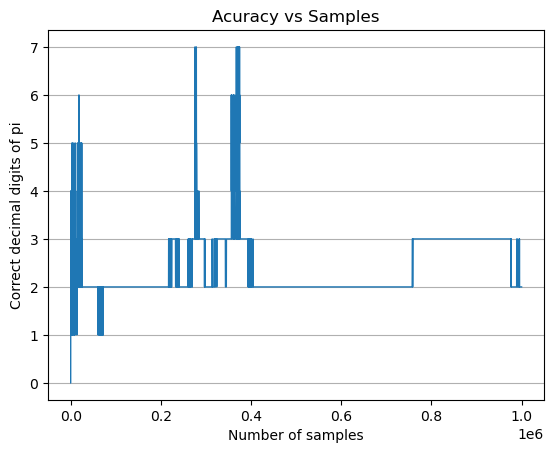

In [5]:
import matplotlib.pyplot as plt

"""
Accuracy Graph
"""

samples, estimates = monte_carlo_convergence(1000000)
digits = np.floor(-np.log10(np.abs(estimates - np.pi) + 1e-10)) #formula to calculate number of correct decimal degits at each step, using 1e-10 to avoid log(0)

fig, aa = plt.subplots() #creates acuracy plot and labels it so can use multiple plt
aa.plot(samples, digits, lw=1)

#Graph styling and labeling

aa.set_xlabel('Number of samples')
aa.set_ylabel('Correct decimal digits of pi')
aa.set_title('Acuracy vs Samples')
aa.grid(axis='y')


plt.show()

<h2>Samples Per Digit</h2>

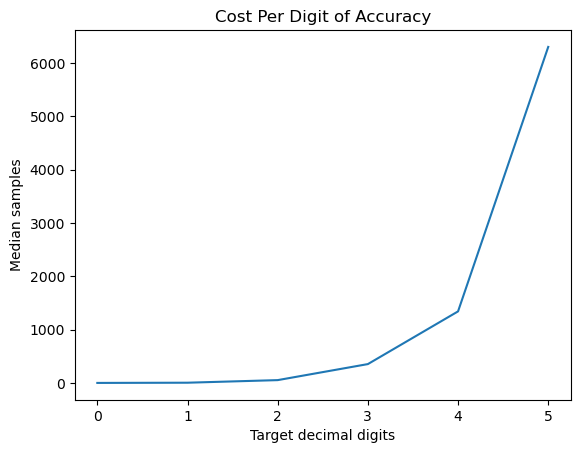

In [6]:
import matplotlib.pyplot as plt

"""
Samples Per Digit
"""

digit_medians = {} #used to get rid of points that didnt have any data
for d, vals in digit_samples.items(): #pulls out each digit and correspond sampling count
    if vals:
        digit_medians[d] = np.median(vals)

digits_list = list(digit_medians.keys()) #becomes x axis

costs_list = list(digit_medians.values()) #becomes the y axis

fig, ab = plt.subplots()

ab.plot(digits_list, costs_list)

ab.set_xlabel('Target decimal digits')
ab.set_ylabel('Median samples')
ab.set_title('Cost Per Digit of Accuracy')

plt.show()

<h2>Convergence Graph</h2>

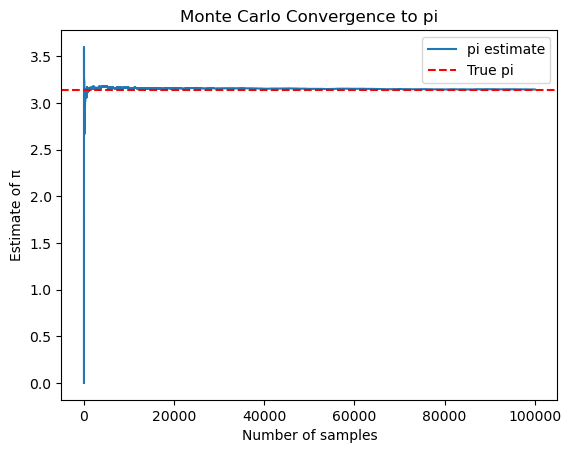

In [7]:
import matplotlib.pyplot as plt

"""
Convergence Graph
"""

samples, estimates = monte_carlo_convergence(100000) #runs the simultion again

fig, ac = plt.subplots() #creates the plot

ac.plot(samples, estimates, label='pi estimate') #graphs samples vs estimates and labels it the pi estimate

ac.axhline(np.pi, color='red', linestyle='--', label='True pi') #adds a line equal to the real value of pi and labels it

ac.set_xlabel('Number of samples')
ac.set_ylabel('Estimate of π')
ac.set_title('Monte Carlo Convergence to pi')

ac.legend()

plt.show()

<h2>Scatter Graph in Circle</h2>

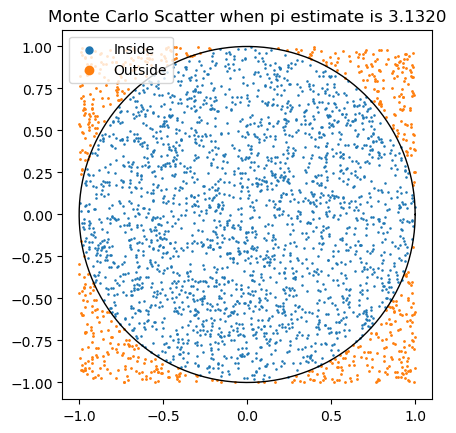

In [8]:
import matplotlib.pyplot as plt

"""
Scatter Graph
"""

n = 3000 #random number of points to generate inside of the circle
x = np.random.uniform(-1, 1, n) #same formula used in monte carlo sim earlier for x points
y = np.random.uniform(-1, 1, n) #same formula used in monte carlo sim earlier for y points
inside = x**2 + y**2 <= 1 #sane mask as before to separate points inside the unit circle and outside it

fig, ad = plt.subplots()

ad.scatter(x[inside],  y[inside], s=0.7, label='Inside') #plots just the point inside the circle
ad.scatter(x[~inside], y[~inside], s=1, label='Outside') #plots just the points outside the circle by flipping the mask

theta = np.linspace(0, 2 * np.pi, 300) #creates the full range of angles in the unit circle
ad.plot(np.cos(theta), np.sin(theta), 'k-', lw=1) #plots the entire unit circle smoothly

ad.set_aspect('equal') #locks the graph to an equal aspect ratio so it appears as a circle

ad.set_title(f'Monte Carlo Scatter when pi estimate is {4 * np.sum(inside) / n:.4f}') #uses the same formula as before to calculate the pi estimate so it matches each time its run

ad.legend(markerscale=6) #makes the legend bigger

plt.show()

<h2>Error Decay Graph</h2>

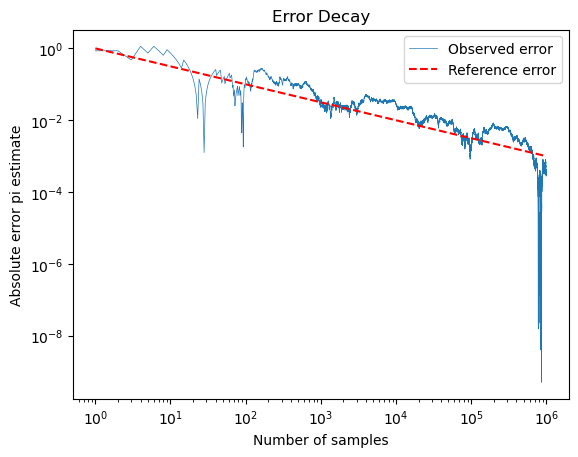

In [9]:
import matplotlib.pyplot as plt

"""
Error Decay
"""

samples, estimates = monte_carlo_convergence(1000000) #runs the simulation yet again

error = np.abs(estimates - np.pi) #calculates the absolute error at every step and creates an array of all the error for each sample

fig, ae = plt.subplots()

ae.plot(samples, error, lw=0.5, label='Observed error') #graphs the error


ref = 1 / np.sqrt(samples) #the formula monte carlo is supposed to follow based on theory


ae.plot(samples, ref,  'r--', lw=1.5, label='Reference error') #graphs the reference error from the theory equation

ae.set_xscale('log') #since everything is so huge had to make the scale log to actually see stuff
ae.set_yscale('log')

ae.set_xlabel('Number of samples')
ae.set_ylabel('Absolute error pi estimate')
ae.set_title('Error Decay')
ae.legend()

plt.show()